# Measuring the Search Lift from NerdWallet's 2025 Super Bowl Ad

**Business question.** How much did NerdWallet's Super Bowl LIX ad increase brand search interest, and how long did the lift last?

**Answer.** Over the four days starting 10 February 2025 (day 0), NerdWallet search interest averaged **23 index points above** its counterfactual, with a placebo-based 95% interval of 17 to 36. The lift was concentrated on day 0, at about **63 points**, roughly 2.7 times the expected level. It fell to 9–12 points on days 1–3 and was back near baseline by day 4. The three estimators that build the counterfactual from comparable searches agree within 2 points (21.6–23.3), while interrupted time series, which leans on NerdWallet's own trend, gives a lower 13–17. The preferred model, a synthetic control, was chosen by an out-of-sample backtest on 38 placebo event dates, and its estimate stays between 22.7 and 24.5 points for every pre-period length from 30 to 100 days.

This notebook contains the full analysis. The [README](README.md) has the business summary.

**Contents**
1. Setup
2. Data and analysis window
3. Exploratory view
4. Causal models: interrupted time series, difference-in-differences, event study, synthetic control
5. Model selection: placebo-date backtest
6. Inference for the preferred model
7. Robustness checks
8. Conclusions

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels.formula.api as smf
from IPython.display import display
from scipy import stats
from scipy.optimize import minimize
from sklearn.base import clone
from sklearn.linear_model import Lasso, LassoCV
from sklearn.model_selection import TimeSeriesSplit
from statsmodels.stats.stattools import durbin_watson

FIG_DIR = Path('figures')
FIG_DIR.mkdir(exist_ok=True)
HAC = {'cov_type': 'HAC', 'cov_kwds': {'maxlags': 7}}   # serial-correlation-robust SEs, one-week lag window


def coef_table(model, terms, index=None):
    """Estimate, 95% CI and p-value for selected terms of a fitted statsmodels model."""
    ci = model.conf_int().loc[terms]
    table = pd.DataFrame({
        'estimate': model.params[terms],
        'ci_lower': ci[0],
        'ci_upper': ci[1],
        'p_value': model.pvalues[terms],
    }).round(3)
    if index is not None:
        table.index = index
    return table


def rmse(x):
    return float(np.sqrt(np.mean(np.square(x))))


def format_date_axis(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.set_xlabel('')

## 2. Data and analysis window

**Source.** Daily Google Trends data for the US, 1 November 2024 to 28 February 2025 ([query](https://trends.google.com/trends/explore?date=2024-11-01%202025-02-28&geo=US&q=%2Fm%2F0hzpb7j,credit%20card%20points,travel%20credit%20card,best%20savings%20account&hl=en)). The four series are indexed together from 0 to 100, where 100 is the highest single day across all of them (here, NerdWallet on day 0). The values measure relative search interest, not search volume.

| Series | Role |
|---|---|
| NerdWallet | Treated series (Google Trends *topic*, which aggregates related brand queries) |
| Credit card points, travel credit card, best savings account | Control queries: personal-finance searches with the same seasonal pattern as NerdWallet's audience, but no direct reason to respond to a NerdWallet brand ad |

The key identifying assumption is that the control queries were not affected by the ad. The bias could run either way. If the ad also increased generic credit-card or savings searches, the controls would rise too and the estimates below would *understate* the true lift. If it diverted searches from the controls to NerdWallet, or lowered their share of all searches on the night, the controls would fall and the estimates would *overstate* it.

**Event date.** Day 0 is 10 February 2025, the first day of elevated NerdWallet search in the series. The game was broadcast on the evening of 9 February US time. The export carries no time-zone parameter, so a late-evening response may be recorded in the next day's bucket. Day −1 (9 February) shows no lift (Section 4.3), so day 0 captures the full response.

**Analysis window.** The same window is used for every model:

| | Window | Rationale |
|---|---|---|
| Pre-period | 90 days, 12 Nov 2024 – 9 Feb 2025 | Covers the holiday season and the shared rise around the turn of the year, so the relationship between NerdWallet and the controls is estimated across the main seasonal movements in the data. The preferred estimate barely changes for pre-periods from 30 to 100 days (Section 7). |
| Post-period | 4 days, 10–13 Feb 2025 (days 0–3) | A single TV exposure should produce an immediate, short-lived response. The daily lift is back near baseline from day 4 (Section 7), so a longer window would mostly add noise and dilute the average. Because any multi-day average depends on the window, day 0 is reported separately. |

In [2]:
event_date = pd.Timestamp('2025-02-10')
preperiod_length = 90   # days before the event used to fit each counterfactual
postperiod_length = 3   # last post-period day relative to the event (days 0-3 inclusive)

start_date = event_date - pd.DateOffset(days=preperiod_length)
end_date = event_date + pd.DateOffset(days=postperiod_length)

treated = 'nerdwallet'
controls = ['credit_card_points', 'travel_credit_card', 'best_savings_account']
labels = {
    'nerdwallet': 'NerdWallet',
    'credit_card_points': 'Credit card points',
    'travel_credit_card': 'Travel credit card',
    'best_savings_account': 'Best savings account',
}

full_df = pd.read_csv(
    'google_trends.csv',
    skiprows=3,
    names=['date', treated, *controls],
    parse_dates=['date'],
    index_col='date',
)
df = full_df.loc[start_date:end_date]

print(f'Full data:       {full_df.index.min():%d %b %Y} to {full_df.index.max():%d %b %Y} ({len(full_df)} days)')
print(f'Analysis window: {df.index.min():%d %b %Y} to {df.index.max():%d %b %Y} '
      f'({(df.index < event_date).sum()} pre-period days, {(df.index >= event_date).sum()} post-period days)')

Full data:       01 Nov 2024 to 28 Feb 2025 (120 days)
Analysis window: 12 Nov 2024 to 13 Feb 2025 (90 pre-period days, 4 post-period days)


## 3. Exploratory view

NerdWallet spikes to the series maximum on day 0. None of the control queries spikes: credit card points and travel credit card fall that day, and best savings account stays within its normal range. All four series rise by about 10–15 points around the turn of the year, a shared seasonal shift (New Year financial planning). That shared shift is why a credible counterfactual needs control queries rather than NerdWallet's own history alone.

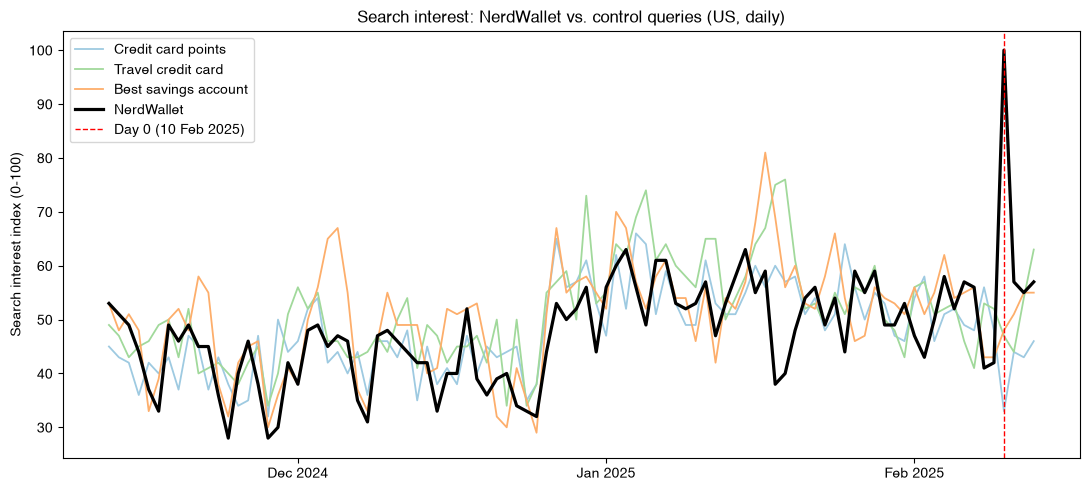

In [3]:
fig, ax = plt.subplots(figsize=(11, 5))
for col, color in zip(controls, ['#9ecae1', '#a1d99b', '#fdae6b']):
    ax.plot(df.index, df[col], color=color, linewidth=1.3, label=labels[col])
ax.plot(df.index, df[treated], color='black', linewidth=2.3, label=labels[treated])
ax.axvline(event_date, color='red', linestyle='--', linewidth=1, label='Day 0 (10 Feb 2025)')
ax.set(title='Search interest: NerdWallet vs. control queries (US, daily)', ylabel='Search interest index (0-100)')
format_date_axis(ax)
ax.legend(loc='upper left')
fig.tight_layout()
fig.savefig(FIG_DIR / 'search_trends.png', dpi=150)

## 4. Causal models

Each method builds NerdWallet's counterfactual (search interest without the ad) in a different way. All use the same window and report effects in index points. The primary estimand is the **average daily effect over days 0–3**, and the **day-0 effect** is reported alongside it.

Daily search data is serially correlated, so ordinary regression standard errors are too small. I use heteroskedasticity- and autocorrelation-consistent (HAC) errors where they are well defined. Section 6 derives the uncertainty for the preferred model from a placebo backtest instead.

### 4.1 Interrupted time series (ITS)

ITS projects NerdWallet's pre-event level and trend forward. The `post` term captures the level shift at the event, and `trend:post` captures the change in slope afterwards. The first specification uses NerdWallet's own history only. The second adds the control queries as covariates to absorb the shared turn-of-year shift.

In [4]:
its_df = df.reset_index()
its_df['trend'] = (its_df['date'] - event_date).dt.days
its_df['post'] = (its_df['trend'] >= 0).astype(int)
post_days = its_df['post'] == 1

its_specs = {
    'NerdWallet only': f'{treated} ~ trend * post',
    'With control covariates': f"{treated} ~ {' + '.join(controls)} + trend * post",
}
its_models = {name: smf.ols(formula, data=its_df).fit(**HAC) for name, formula in its_specs.items()}


def its_daily_effect(model):
    return model.params['post'] + model.params['trend:post'] * its_df.loc[post_days, 'trend']


its_summary = pd.DataFrame({
    name: {
        'post (level shift)': m.params['post'],
        'trend:post (slope change)': m.params['trend:post'],
        'p-value, post': m.pvalues['post'],
        'R-squared': m.rsquared,
        'Durbin-Watson': durbin_watson(m.resid),
        'Day-0 effect': its_daily_effect(m).iloc[0],
        'Average effect, days 0-3': its_daily_effect(m).mean(),
    }
    for name, m in its_models.items()
}).round(3)
its_model = its_models['With control covariates']
its_summary

,NerdWallet only,With control covariates
post (level shift),32.966,39.485
trend:post (slope change),-13.254,-15.140
"p-value, post",0.000,0.000
R-squared,0.407,0.637
Durbin-Watson,1.174,1.468
Day-0 effect,32.966,39.485
"Average effect, days 0-3",13.085,16.774


**Validation: in-sample and out-of-sample fit.** For both specifications, I compare the in-sample fit with an out-of-sample forecast: each model is refitted on pre-period data only and projected over days 0–3, which gives a counterfactual that is not influenced by the four post-event observations. The left panel shows the specification with controls against actual values, plus the counterfactual obtained by switching the post-event terms off. The right panel shows the out-of-sample forecasts of both specifications.

,NerdWallet only,With control covariates
in-sample R-squared,0.41,0.64
pre-period RMSE (pre-only fit),7.52,5.64
"out-of-sample effect, day 0",46.07,54.36
"out-of-sample effect, days 0-3",13.09,18.09


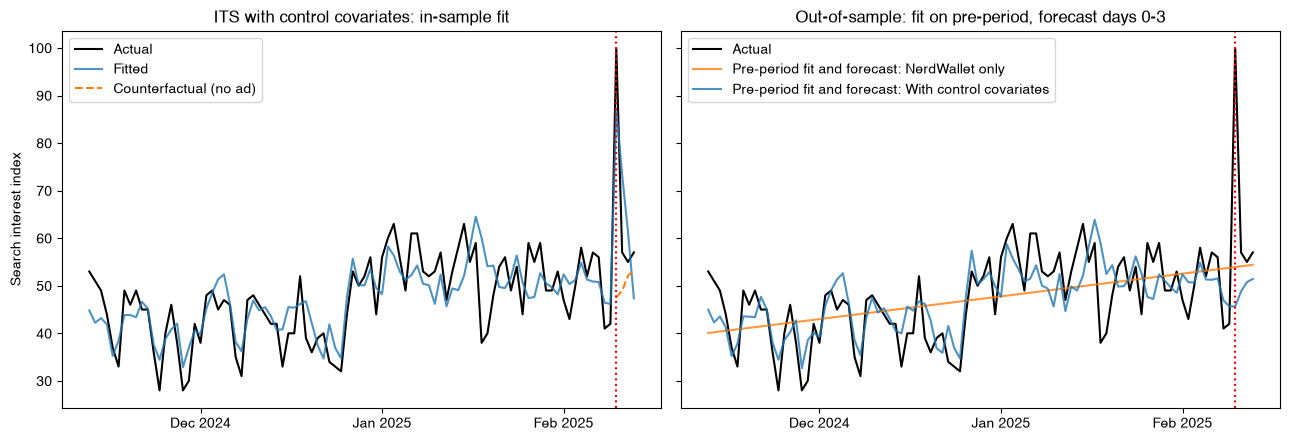

In [5]:
its_df['fitted'] = its_model.predict(its_df)
its_df['counterfactual'] = its_model.predict(its_df.assign(post=0))

its_oos = {}
for name, formula in its_specs.items():
    pre_formula = formula.replace(' * post', '')   # same model without the post-event terms
    pre_model = smf.ols(pre_formula, data=its_df[~post_days]).fit()
    its_df[f'forecast: {name}'] = pre_model.predict(its_df)
    oos_gap = (its_df[treated] - its_df[f'forecast: {name}'])[post_days]
    its_oos[name] = {
        'in-sample R-squared': its_models[name].rsquared,
        'pre-period RMSE (pre-only fit)': rmse(pre_model.resid),
        'out-of-sample effect, day 0': oos_gap.iloc[0],
        'out-of-sample effect, days 0-3': oos_gap.mean(),
    }
display(pd.DataFrame(its_oos).round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
axes[0].plot(its_df['date'], its_df[treated], color='black', label='Actual')
axes[0].plot(its_df['date'], its_df['fitted'], color='tab:blue', alpha=0.8, label='Fitted')
axes[0].plot(its_df.loc[post_days, 'date'], its_df.loc[post_days, 'counterfactual'],
             color='tab:orange', linestyle='--', label='Counterfactual (no ad)')
axes[0].set_title('ITS with control covariates: in-sample fit')
axes[1].plot(its_df['date'], its_df[treated], color='black', label='Actual')
for name, color in zip(its_specs, ['tab:orange', 'tab:blue']):
    axes[1].plot(its_df['date'], its_df[f'forecast: {name}'], color=color, alpha=0.8, label=f'Pre-period fit and forecast: {name}')
axes[1].set_title('Out-of-sample: fit on pre-period, forecast days 0-3')
for ax in axes:
    ax.axvline(event_date, color='red', linestyle=':')
    format_date_axis(ax)
    ax.legend(loc='upper left')
axes[0].set_ylabel('Search interest index')
fig.tight_layout()

**Result.** With NerdWallet's own history only, ITS estimates a 33.0-point level shift and a 13.1-point average effect over days 0–3. Its R² is just 0.41, because the model has to absorb the turn-of-year shift through a single linear trend. Adding the control queries raises R² to 0.64, and the estimates rise to a 39.5-point level shift (slope change −15.1 points per day) and a 16.8-point average effect. Out of sample, the NerdWallet-only specification gives 13.1 on average and 46.1 on day 0 (pre-period RMSE 7.5), and the specification with controls gives 18.1 and 54.4 (RMSE 5.6). The controls improve both the fit and the forecast, and in both specifications the out-of-sample day-0 effect is well above the in-sample level shift.

**Limitation.** The post-event terms are identified from four observations, the first of which is the spike. A straight-line decay is a poor shape for a one-day surge, so ITS understates the day-0 effect. The HAC p-values (all < 0.001) are only indicative with so few post-event points. ITS serves as a baseline.

### 4.2 Difference-in-differences (DiD)

**Baseline: naive pre/post comparison.** This is NerdWallet's post-event average minus its pre-event average, with no counterfactual.

In [6]:
prepost_model = smf.ols(f'{treated} ~ post', data=its_df).fit(**HAC)
coef_table(prepost_model, ['post'])

,estimate,ci_lower,ci_upper,p_value
post,20.328,9.884,30.771,0.0


The naive difference is 20.3 points. It ignores the turn-of-year rise shared by all queries, so it mixes part of that seasonal shift into the estimate. DiD corrects for this by using the control queries as comparison units.

**Two-way fixed effects (TWFE) DiD.** The data is reshaped to one row per query and date. Query fixed effects absorb level differences between queries, and date fixed effects absorb shocks that hit all queries on the same day. `treated:post` is the DiD estimate. In this balanced panel it equals the change in the gap between NerdWallet and the equal-weighted control average from the pre-period to the post-period.

In [7]:
panel = df.reset_index().melt(id_vars='date', var_name='query', value_name='value')
panel['trend'] = (panel['date'] - event_date).dt.days
panel['post'] = (panel['trend'] >= 0).astype(int)
panel['treated'] = (panel['query'] == treated).astype(int)

did_model = smf.ols(f"value ~ C(query, Treatment(reference='{treated}')) + C(date) + treated:post", data=panel).fit()
print(f'R-squared: {did_model.rsquared:.3f}   (conventional SEs; see Section 6 for placebo-based inference)')
coef_table(did_model, ['treated:post'])

R-squared: 0.695   (conventional SEs; see Section 6 for placebo-based inference)


,estimate,ci_lower,ci_upper,p_value
treated:post,21.881,14.891,28.872,0.0


**Validation: parallel pre-trends.** DiD assumes NerdWallet and the controls would have moved in parallel without the ad. I test for a linear divergence by adding a NerdWallet-specific trend to the model on pre-period data only, and plot the daily gap between NerdWallet and the control average.

Pre-period differential trend (NerdWallet vs. controls, index points per day):


,estimate,ci_lower,ci_upper,p_value
treated:trend,-0.008,-0.059,0.044,0.769


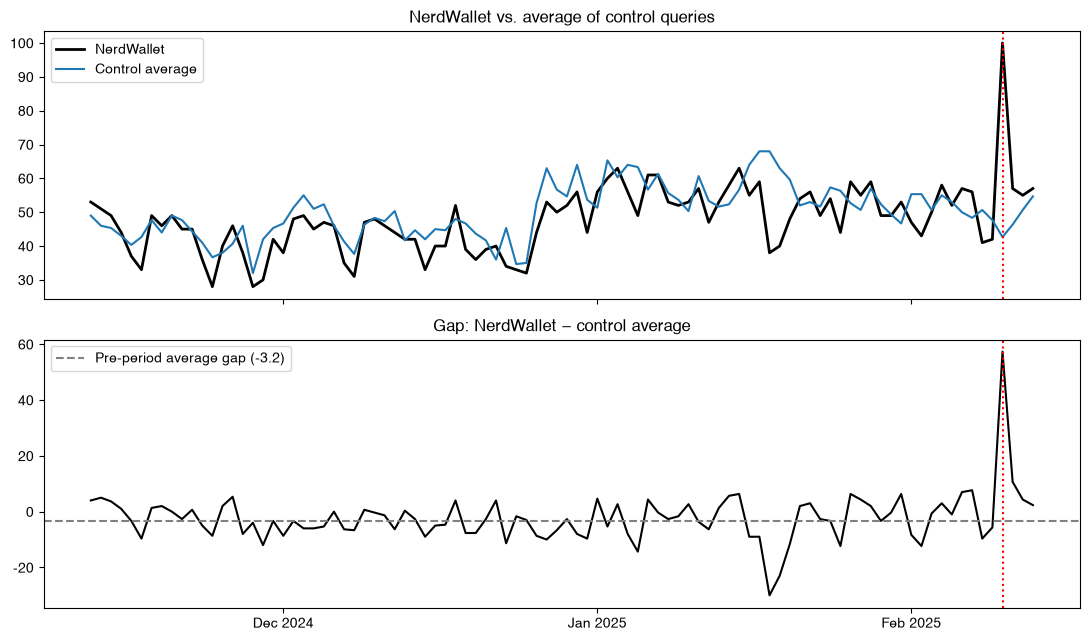

In [8]:
pretrend_model = smf.ols('value ~ C(query) + C(date) + treated:trend', data=panel[panel['post'] == 0]).fit()
pretrend = coef_table(pretrend_model, ['treated:trend'])
print('Pre-period differential trend (NerdWallet vs. controls, index points per day):')
display(pretrend)

gap_df = df.assign(control_avg=df[controls].mean(axis=1))
gap_df['gap'] = gap_df[treated] - gap_df['control_avg']
pre_gap = gap_df.loc[gap_df.index < event_date, 'gap']

fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
axes[0].plot(gap_df.index, gap_df[treated], color='black', linewidth=2, label='NerdWallet')
axes[0].plot(gap_df.index, gap_df['control_avg'], color='tab:blue', label='Control average')
axes[0].set_title('NerdWallet vs. average of control queries')
axes[0].legend(loc='upper left')
axes[1].plot(gap_df.index, gap_df['gap'], color='black')
axes[1].axhline(pre_gap.mean(), color='gray', linestyle='--', label=f'Pre-period average gap ({pre_gap.mean():.1f})')
axes[1].set_title('Gap: NerdWallet − control average')
axes[1].legend(loc='upper left')
for ax in axes:
    ax.axvline(event_date, color='red', linestyle=':')
    format_date_axis(ax)
fig.tight_layout()

**Result.** The DiD estimate is **21.9 points** on average over days 0–3. Its conventional 95% CI is 14.9 to 28.9, which understates the uncertainty (see Section 6). There is no evidence of a linear differential pre-trend (−0.008 points per day, p = 0.77), and the gap plot shows no drift before the event. This is consistent with parallel trends, although the test only checks for a linear divergence.

### 4.3 Event study

**Single post-period indicator.** NerdWallet is regressed on the control queries plus one indicator for days 0–3, with HAC errors.

In [9]:
es_df = df.reset_index()
es_df['t'] = (es_df['date'] - event_date).dt.days
es_df['post'] = (es_df['t'] >= 0).astype(int)

es_single = smf.ols(f"{treated} ~ {' + '.join(controls)} + post", data=es_df).fit(**HAC)
coef_table(es_single, ['post'])

,estimate,ci_lower,ci_upper,p_value
post,20.637,9.16,32.113,0.0


**Time-varying effects.** The single indicator is replaced with one indicator per day from −7 to +3, with days −90 to −8 as the reference period. The pre-event coefficients test for anticipation or pre-existing divergence, and the post-event coefficients show how long the effect lasts. Each daily indicator matches exactly one observation, so HAC errors are not usable here (the indicator's residual is zero by construction), and conventional errors are reported.

In [10]:
event_window = range(-7, postperiod_length + 1)
es_df['t_bin'] = np.where(es_df['t'].between(event_window.start, event_window.stop - 1), es_df['t'].astype(str), 'base')

event_model = smf.ols(
    f"{treated} ~ {' + '.join(controls)} + C(t_bin, Treatment(reference='base'))",
    data=es_df,
).fit()

day_term = "C(t_bin, Treatment(reference='base'))[T.{}]".format
es_results = coef_table(event_model, [day_term(t) for t in event_window], index=pd.Index(event_window, name='day'))
pre_event_test = event_model.f_test(', '.join(f'{day_term(t)} = 0' for t in range(-7, 0)))

print(f'Joint test, days -7 to -1 all zero: F = {float(pre_event_test.fvalue):.2f}, p = {float(pre_event_test.pvalue):.2f}')
print(f'Average effect, days 0-3: {es_results.loc[0:, "estimate"].mean():.1f}')
es_results

Joint test, days -7 to -1 all zero: F = 0.71, p = 0.66
Average effect, days 0-3: 21.6


,estimate,ci_lower,ci_upper,p_value
day,,,,
-7,2.053,-9.922,14.029,0.734
-6,5.653,-6.407,17.714,0.354
-5,2.864,-9.094,14.823,0.635
-4,8.589,-3.473,20.651,0.160
-3,7.693,-4.576,19.962,0.216
-2,-4.302,-16.521,7.917,0.485
-1,-1.227,-13.224,10.770,0.839
0,58.646,46.206,71.085,0.000
1,11.727,-0.274,23.729,0.055


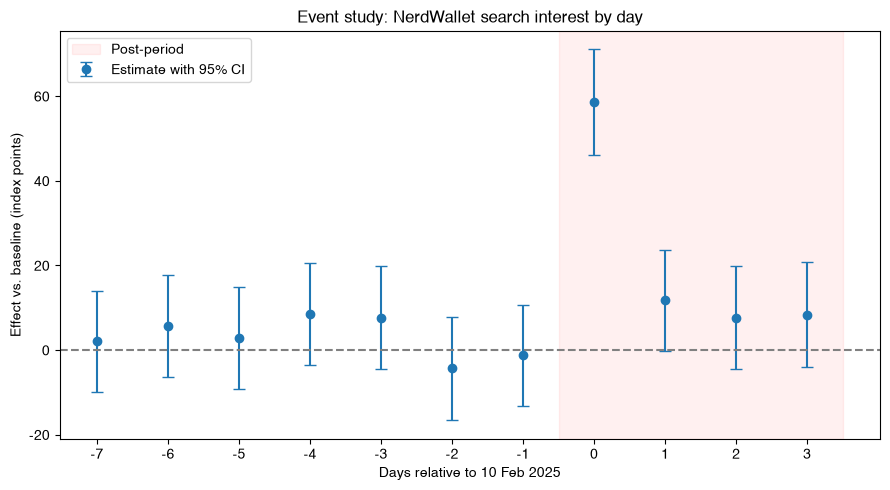

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.axvspan(-0.5, postperiod_length + 0.5, color='red', alpha=0.06, label='Post-period')
ax.errorbar(
    es_results.index, es_results['estimate'],
    yerr=[es_results['estimate'] - es_results['ci_lower'], es_results['ci_upper'] - es_results['estimate']],
    fmt='o', capsize=4, color='tab:blue', label='Estimate with 95% CI',
)
ax.axhline(0, color='gray', linestyle='--')
ax.set_xticks(list(event_window))
ax.set(xlabel='Days relative to 10 Feb 2025', ylabel='Effect vs. baseline (index points)',
       title='Event study: NerdWallet search interest by day')
ax.legend(loc='upper left')
fig.tight_layout()
fig.savefig(FIG_DIR / 'event_study.png', dpi=150)

**Result.** The single-indicator model gives 20.6 points over days 0–3 (HAC 95% CI 9.2 to 32.1). The daily model puts the effect at **58.6 points on day 0** (95% CI 46.2 to 71.1). Days 1–3 are smaller, at 7.6–11.7 points, and not individually significant (p = 0.06 to 0.21). The daily estimates average 21.6 points over days 0–3. With CIs of about ±12 points, persistence beyond day 0 can be neither confirmed nor ruled out from the event study alone. Section 7 shows the lift is back near baseline from day 4.

**Validation.** The pre-event coefficients are not individually significant (all p > 0.15) or jointly significant (F-test p = 0.66). Days −7 to −3 do run a few points above baseline, so this test can only rule out large anticipation effects, not small ones.

### 4.4 Synthetic control

The synthetic control builds a weighted average of the control queries (the *donor pool*) that tracks NerdWallet over the pre-period, and uses it as the counterfactual afterwards. The weights follow the classic specification (Abadie, Diamond and Hainmueller, 2010): they are non-negative, sum to one and are fitted on pre-period data only. The constraint makes the synthetic series move as an average of the donors' movements, so it interpolates between comparable searches rather than extrapolating from them. With only three donors, it also prevents the weights from fitting pre-period noise.

NerdWallet's pre-period mean (46.9) is below that of every donor (48.3–51.3), so no weighted average of the donors can match its level. The synthetic series is therefore shifted by its average pre-period gap to NerdWallet, which amounts to a difference-in-differences between NerdWallet and its synthetic version. The shift changes the level of the synthetic series but not the weights or how the series moves. Section 5 selects this specification over four alternatives on out-of-sample error.

In [12]:
def synthetic_control(data, treated_name, donor_names, event=None, level='netted'):
    """Synthetic control with non-negative donor weights that sum to one, fitted on the pre-period.

    level='netted':   weights fitted on pre-period levels, then the series is shifted by the pre-period mean gap
    level='demeaned': weights fitted on demeaned pre-period data, with the same shift
    level='none':     no shift (Abadie, Diamond and Hainmueller, 2010, in its outcome-only form)
    Returns the synthetic series for the whole window, the weights and the level shift.
    """
    event = event_date if event is None else event
    pre = data.loc[data.index < event]
    y, X = pre[treated_name].values, pre[donor_names].values
    if level == 'demeaned':
        y, X = y - y.mean(), X - X.mean(axis=0)
    solution = minimize(
        lambda w: np.sum((y - X @ w) ** 2),
        x0=np.full(len(donor_names), 1 / len(donor_names)),
        method='SLSQP',
        bounds=[(0, 1)] * len(donor_names),
        constraints={'type': 'eq', 'fun': lambda w: w.sum() - 1},
    )
    assert solution.success, solution.message
    weights = pd.Series(solution.x, index=donor_names)
    shift = 0.0 if level == 'none' else pre[treated_name].mean() - pre[donor_names].mean() @ weights
    return data[donor_names] @ weights + shift, weights, shift


sc_synthetic, sc_weights, sc_level = synthetic_control(df, treated, controls)
sc_gap = df[treated] - sc_synthetic

print('Pre-period means:', df.loc[df.index < event_date].mean().round(1).rename(labels).to_dict())
print('Weights:', {labels[c]: round(float(w), 3) for c, w in sc_weights.items()}, f'(sum {sc_weights.sum():.2f})')
print(f'Level shift (pre-period mean gap): {sc_level:.2f} points')
print(f'Pre-period RMSE: {rmse(sc_gap.loc[sc_gap.index < event_date]):.2f}')
print(f'Effect: day 0 {sc_gap.loc[event_date]:.1f}, average over days 0-3 {sc_gap.loc[event_date:].mean():.1f}')

Pre-period means: {'NerdWallet': 46.9, 'Credit card points': 48.3, 'Travel credit card': 51.3, 'Best savings account': 50.8}
Weights: {'Credit card points': 0.542, 'Travel credit card': 0.0, 'Best savings account': 0.458} (sum 1.00)
Level shift (pre-period mean gap): -2.52 points
Pre-period RMSE: 6.09
Effect: day 0 62.7, average over days 0-3 23.3


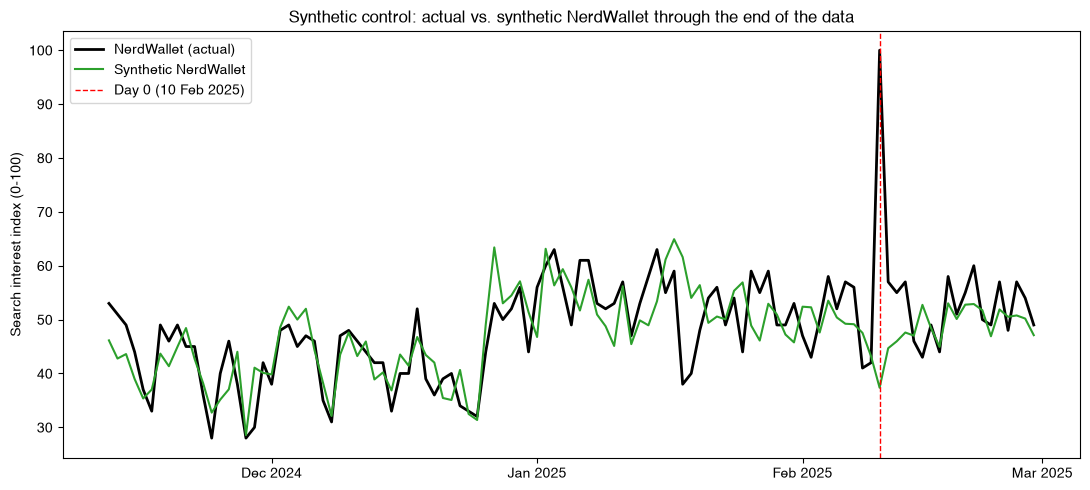

In [13]:
sc_extended = full_df.loc[start_date:]
sc_extended_synthetic = sc_extended[controls] @ sc_weights + sc_level

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(sc_extended.index, sc_extended[treated], color='black', linewidth=2, label='NerdWallet (actual)')
ax.plot(sc_extended.index, sc_extended_synthetic, color='tab:green', linewidth=1.5, label='Synthetic NerdWallet')
ax.axvline(event_date, color='red', linestyle='--', linewidth=1, label='Day 0 (10 Feb 2025)')
ax.set(title='Synthetic control: actual vs. synthetic NerdWallet through the end of the data',
       ylabel='Search interest index (0-100)')
format_date_axis(ax)
ax.legend(loc='upper left')
fig.tight_layout()
fig.savefig(FIG_DIR / 'synthetic_control.png', dpi=150)

**Result.** The weights are 0.54 on credit card points and 0.46 on best savings account, and travel credit card gets zero weight. Before the shift, the synthetic series runs on average 2.5 points above NerdWallet in the pre-period, and the level shift removes that offset. The shifted series tracks NerdWallet through the pre-period, including the turn-of-year rise (RMSE 6.1). The estimated effect is **62.7 points on day 0** and **23.3 points on average over days 0–3**. After day 3 the two series run together again through the end of February.

**Alternative specifications.** For comparison, the table below also fits the synthetic control in four other ways. The *demeaned* synthetic control (Ferman and Pinto, 2021) fits the weights on demeaned data, so that they match NerdWallet's movements rather than its level. The original Abadie specification applies no level shift. The two Lasso regressions drop the constraint on the weights: one with a fixed penalty (`alpha = 0.1`), and one with `alpha` tuned by `LassoCV` over `TimeSeriesSplit` folds, so that each validation fold lies after its training data.

In [14]:
def summarize_sc(synthetic, weights, level):
    gap = df[treated] - synthetic
    pre_gap = gap.loc[gap.index < event_date]
    return {
        **{f'weight: {labels[c]}': w for c, w in zip(controls, weights)},
        'sum of weights': np.sum(weights),
        'level shift / intercept': level,
        'pre-period mean gap': pre_gap.mean(),
        'pre-period RMSE': rmse(pre_gap),
        'Day-0 effect': gap.loc[event_date],
        'Average effect, days 0-3': gap.loc[event_date:].mean(),
    }


pre = df.loc[df.index < event_date]
sc_variants = {
    'Netted (main)': summarize_sc(sc_synthetic, sc_weights, sc_level),
    'Demeaned': summarize_sc(*synthetic_control(df, treated, controls, level='demeaned')),
    'No level shift': summarize_sc(*synthetic_control(df, treated, controls, level='none')),
}
lasso_specs = {
    'Lasso, alpha = 0.1': Lasso(alpha=0.1),
    'LassoCV': LassoCV(cv=TimeSeriesSplit(n_splits=5), alphas=np.logspace(-3, 1, 50), max_iter=10000),
}
for name, estimator in lasso_specs.items():
    model = estimator.fit(pre[controls], pre[treated])
    sc_variants[name] = summarize_sc(pd.Series(model.predict(df[controls]), index=df.index), model.coef_, model.intercept_)
print(f"LassoCV alpha: {lasso_specs['LassoCV'].alpha_:.2f}")
pd.DataFrame(sc_variants).round(2)

LassoCV alpha: 2.22


,Netted (main),Demeaned,No level shift,"Lasso, alpha = 0.1",LassoCV
weight: Credit card points,0.54,0.45,0.54,0.27,0.25
weight: Travel credit card,0.00,0.01,0.00,0.00,0.00
weight: Best savings account,0.46,0.54,0.46,0.48,0.47
sum of weights,1.00,1.00,1.00,0.76,0.72
level shift / intercept,-2.52,-2.76,0.00,9.21,11.01
pre-period mean gap,0.00,-0.00,-2.52,0.00,-0.00
pre-period RMSE,6.09,6.04,6.59,5.76,5.76
Day-0 effect,62.65,61.47,60.13,58.60,58.16
"Average effect, days 0-3",23.35,22.56,20.83,21.47,21.31


The three constrained specifications put almost all of the weight on credit card points and best savings account. Without the level shift, the 2.5-point pre-period offset carries into the post-period and the estimate falls to 20.8. The demeaned version fits the weights to NerdWallet's movements rather than its level and gives 22.6. The Lasso weights sum to only 0.72–0.76, with an intercept of 9–11 points making up the difference, so the Lasso fit is a scaled regression of NerdWallet on the controls rather than a weighted average of them. All five specifications give 20.8 to 23.3 points over days 0–3, so the estimate does not depend materially on how the weights are fitted. Section 5.1 chooses between them on out-of-sample error.

**In-space placebo test.** Each control query in turn is treated as if it had run the ad. Its synthetic control is built from the other controls (NerdWallet excluded from the donor pool), and its "effect" is estimated with the same specification. The three placebo effects show how large an effect the method produces when there is none. I summarize them in three ways: a 95% range from their mean and standard deviation, a small-sample prediction interval for a single new estimate, and an exact rank-based p-value.

In [15]:
def sc_average_effect(data, treated_name, donor_names, event=None):
    event = event_date if event is None else event
    synthetic, _, _ = synthetic_control(data, treated_name, donor_names, event)
    return float((data[treated_name] - synthetic).loc[event:].mean())


in_space = pd.Series({labels[q]: sc_average_effect(df, q, [c for c in controls if c != q]) for q in controls})
in_space[labels[treated]] = sc_average_effect(df, treated, controls)
placebo_effects, sc_estimate = in_space.drop(labels[treated]), in_space[labels[treated]]

n_placebo = len(placebo_effects)
placebo_mean, placebo_sd = placebo_effects.mean(), placebo_effects.std()
# Prediction-interval scale for one new draw when mean and SD are both estimated from n placebos
pred_sd = placebo_sd * np.sqrt(1 + 1 / n_placebo)
t_crit = stats.t.ppf(0.975, df=n_placebo - 1)
t_stat = (sc_estimate - placebo_mean) / pred_sd
t_p = 2 * stats.t.sf(abs(t_stat), df=n_placebo - 1)
rank_p = (in_space.abs() >= abs(sc_estimate)).mean()

print(f'Placebo effects: mean {placebo_mean:.1f}, SD {placebo_sd:.1f}')
print(f'95% placebo range, normal (mean +/- 1.96 SD): {placebo_mean - 1.96 * placebo_sd:.1f} to {placebo_mean + 1.96 * placebo_sd:.1f}')
print(f'95% prediction interval, t with {n_placebo - 1} df: {placebo_mean - t_crit * pred_sd:.1f} to {placebo_mean + t_crit * pred_sd:.1f}')
print(f'NerdWallet estimate: {sc_estimate:.1f} (t = {t_stat:.2f}, p = {t_p:.2f})')
print(f'Rank-based p-value: {rank_p:.2f} (the minimum attainable with three placebos is 0.25)')
in_space.sort_values().round(1).rename('average effect, days 0-3').to_frame()

Placebo effects: mean 1.0, SD 7.6
95% placebo range, normal (mean +/- 1.96 SD): -13.8 to 15.8
95% prediction interval, t with 2 df: -36.6 to 38.6
NerdWallet estimate: 23.3 (t = 2.56, p = 0.12)
Rank-based p-value: 0.25 (the minimum attainable with three placebos is 0.25)


,"average effect, days 0-3"
Credit card points,-7.7
Best savings account,5.0
Travel credit card,5.7
NerdWallet,23.3


NerdWallet's effect (23.3) is the largest of the four, while the placebo effects range from −7.7 to 5.7. It lies outside the normal-approximation 95% range of the placebo effects (−13.8 to 15.8). That range treats a standard deviation estimated from only three values as known, though. The small-sample prediction interval, which accounts for estimating both the mean and the SD, is −36.6 to 38.6 and contains the estimate (t = 2.56, p = 0.12), and the exact rank-based p-value cannot go below 0.25. An in-space test with three donors is therefore suggestive but cannot establish significance on its own. The in-time placebo backtest in Section 5 provides 38 placebo draws, and Section 6 bases inference on it.

## 5. Model selection: placebo-date backtest

**Metric.** The best test of a counterfactual model is how well it predicts outcomes when the true effect is known to be zero. I re-run the models on **38 placebo event dates** (31 Dec 2024 – 6 Feb 2025), each with a 60-day pre-period and a 4-day post-period that ends before the real event. Every "effect" these runs estimate is pure model error. The selection metric is the **RMSE of the placebo average effects (days 0–3)**, the out-of-sample error on the same estimand as the headline. The mean placebo effect (bias) is reported alongside it. A 60-day pre-period is the longest the data allows for this range of dates, since the data starts on 1 November. In-sample pre-period RMSE is reported for reference only, because every model is fit to that same pre-period and can look good on it without forecasting well.

The backtest is used twice: first to choose the synthetic control specification, then to choose between the four methods.

In [16]:
def its_effects(data, event):
    x = data.reset_index()
    x['trend'] = (x['date'] - event).dt.days
    x['post'] = (x['trend'] >= 0).astype(int)
    m = smf.ols(its_specs['With control covariates'], data=x).fit()
    effect = m.params['post'] + m.params['trend:post'] * x.loc[x['post'] == 1, 'trend']
    return effect.iloc[0], effect.mean()


def did_effects(data, event):
    gap = data[treated] - data[controls].mean(axis=1)
    gap = gap - gap.loc[gap.index < event].mean()   # equals the TWFE treated:post estimate in a balanced panel
    return gap.loc[event], gap.loc[event:].mean()


def es_effects(data, event):
    x = data.reset_index()
    x['t'] = (x['date'] - event).dt.days
    x['t_bin'] = np.where(x['t'].between(-7, postperiod_length), x['t'].astype(str), 'base')
    m = smf.ols(f"{treated} ~ {' + '.join(controls)} + C(t_bin, Treatment(reference='base'))", data=x).fit()
    daily = [m.params[day_term(t)] for t in range(postperiod_length + 1)]
    return daily[0], float(np.mean(daily))


def constrained_sc_effects(level):
    def effects(data, event):
        synthetic, _, _ = synthetic_control(data, treated, controls, event, level=level)
        gap = data[treated] - synthetic
        return gap.loc[event], gap.loc[event:].mean()
    return effects


def lasso_sc_effects(estimator):
    def effects(data, event):
        pre = data.loc[data.index < event]
        model = clone(estimator).fit(pre[controls], pre[treated])
        gap = data[treated] - model.predict(data[controls])
        return gap.loc[event], gap.loc[event:].mean()
    return effects


sc_effects = constrained_sc_effects(level='netted')
models = {
    'Interrupted time series': its_effects,
    'Difference-in-differences': did_effects,
    'Event study': es_effects,
    'Synthetic control': sc_effects,
}

# Sanity check: the functions reproduce the Section 4 estimates on the real event
actual = pd.DataFrame({name: fn(df, event_date) for name, fn in models.items()}, index=['day 0', 'days 0-3']).T
assert np.isclose(actual.loc['Difference-in-differences', 'days 0-3'], did_model.params['treated:post'])
assert np.isclose(actual.loc['Synthetic control', 'days 0-3'], sc_gap.loc[event_date:].mean())

placebo_pre = 60


def placebo_dates_for(pre_length):
    """Fake event dates whose pre-period fits in the data and whose 4-day post-period ends before the real event."""
    return pd.date_range(full_df.index.min() + pd.Timedelta(days=pre_length),
                         event_date - pd.Timedelta(days=postperiod_length + 1))


def run_placebos(model_fns, pre_length=placebo_pre):
    """Re-estimate each model at every placebo date; one row per date and model."""
    rows = []
    for fake in placebo_dates_for(pre_length):
        window = full_df.loc[fake - pd.Timedelta(days=pre_length):fake + pd.Timedelta(days=postperiod_length)]
        for name, fn in model_fns.items():
            day0, avg = fn(window, fake)
            rows.append({'placebo_date': fake, 'model': name, 'day 0': day0, 'days 0-3': avg})
    return pd.DataFrame(rows)


def score_placebos(placebo_rows, order):
    return placebo_rows.groupby('model').agg(
        placebo_rmse=('days 0-3', rmse),
        placebo_bias=('days 0-3', 'mean'),
        placebo_rmse_day0=('day 0', rmse),
    ).reindex(order)


placebo_dates = placebo_dates_for(placebo_pre)
print(f'{placebo_dates.size} placebo dates: {placebo_dates.min():%d %b %Y} to {placebo_dates.max():%d %b %Y}')

38 placebo dates: 31 Dec 2024 to 06 Feb 2025


### 5.1 Synthetic control specification

Section 4.4 fitted the synthetic control in five ways. Their in-sample fit cannot decide between them: the Lasso specifications fit the pre-period best (RMSE 5.8) only because they have the most freedom, with weights of any size and a free intercept. Each specification is therefore scored on the placebo backtest.

In [17]:
sc_variant_fns = {
    'Netted (main)': sc_effects,
    'Demeaned': constrained_sc_effects(level='demeaned'),
    'No level shift': constrained_sc_effects(level='none'),
    **{name: lasso_sc_effects(estimator) for name, estimator in lasso_specs.items()},
}
sc_variant_table = score_placebos(run_placebos(sc_variant_fns), sc_variant_fns)
sc_variant_table['in_sample_pre_rmse'] = pd.DataFrame(sc_variants).T['pre-period RMSE']
sc_variant_table['days 0-3'] = pd.DataFrame(sc_variants).T['Average effect, days 0-3']
sc_variant_table.round(2)

,placebo_rmse,placebo_bias,placebo_rmse_day0,in_sample_pre_rmse,days 0-3
model,,,,,
Netted (main),4.69,0.74,7.76,6.09,23.35
Demeaned,5.30,0.20,8.09,6.04,22.56
No level shift,4.99,-2.00,7.95,6.59,20.83
"Lasso, alpha = 0.1",5.41,1.46,7.77,5.76,21.47
LassoCV,5.67,1.96,7.86,5.76,21.31


**Selected specification: netted synthetic control.** The weights are non-negative, sum to one and are fitted on pre-period levels, and the synthetic series is shifted by its pre-period mean gap to NerdWallet.

1. **Lowest out-of-sample error.** Its placebo RMSE is 4.69, against 4.99–5.67 for the alternatives. It also has the lowest day-0 placebo RMSE (7.76).
2. **Small bias.** Its placebo bias (+0.7 points) is small relative to its RMSE. The specification without a level shift comes closest on RMSE (4.99), but it underestimates by 2.0 points on average. That bias is the pre-period level offset, which is known before the event and which the netted version removes.
3. **First place does not depend on the placebo design.** It ranks first of the five specifications with 40-, 50- and 60-day placebo pre-periods (Section 5.2), although the order of the others changes.

The margins between the constrained specifications are small (0.3–0.6 points of RMSE) and their estimates span 20.8 to 23.3, so the choice is a consistent but modest improvement rather than a decisive one.
4. **Interpretable weights.** The counterfactual is 54% credit card points and 46% best savings account, shifted by a constant. The Lasso fits have the best in-sample RMSE but do worse out of sample, so their extra flexibility fits pre-period noise rather than structure.

The demeaned version, which fits the weights to NerdWallet's movements rather than its level, is less accurate out of sample here (5.30 against 4.69).

### 5.2 Choice of method

In [18]:
placebos = run_placebos(models)
in_sample_rmse = {
    'Interrupted time series': rmse(its_model.resid[~post_days]),
    'Difference-in-differences': rmse(pre_gap - pre_gap.mean()),
    'Event study': rmse(event_model.resid[es_df['t_bin'] == 'base']),
    'Synthetic control': rmse(sc_gap.loc[sc_gap.index < event_date]),
}
comparison = score_placebos(placebos, models).join(pd.Series(in_sample_rmse, name='in_sample_pre_rmse')).join(actual)
# Empirical p-value per model: share of placebo estimates at least as large as the real one (days 0-3)
comparison['empirical_p'] = [
    ((placebos.loc[placebos['model'] == name, 'days 0-3'].abs() >= abs(actual.loc[name, 'days 0-3'])).sum() + 1)
    / (len(placebo_dates) + 1)
    for name in comparison.index
]
comparison.sort_values('placebo_rmse').round(3)

,placebo_rmse,placebo_bias,placebo_rmse_day0,in_sample_pre_rmse,day 0,days 0-3,empirical_p
model,,,,,,,
Synthetic control,4.692,0.743,7.759,6.086,62.654,23.349,0.026
Difference-in-differences,5.249,0.675,8.264,6.430,60.548,21.881,0.026
Event study,5.488,1.854,8.098,5.813,58.646,21.590,0.026
Interrupted time series,5.855,-0.127,7.963,5.671,39.485,16.774,0.026


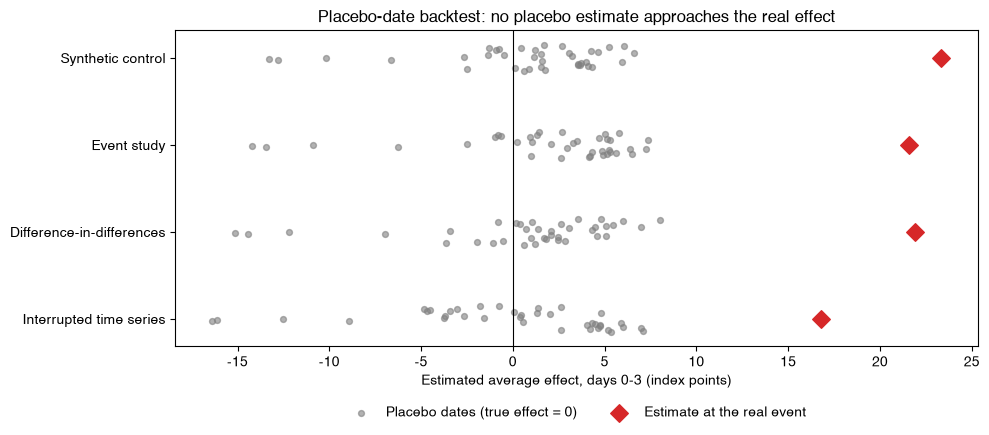

In [19]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for i, name in enumerate(models):
    values = placebos.loc[placebos['model'] == name, 'days 0-3']
    ax.scatter(values, np.full(len(values), i) + np.linspace(-0.15, 0.15, len(values)),
               color='gray', alpha=0.6, s=18, label='Placebo dates (true effect = 0)' if i == 0 else None)
    ax.scatter(actual.loc[name, 'days 0-3'], i, color='tab:red', s=80, marker='D',
               label='Estimate at the real event' if i == 0 else None)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_yticks(range(len(models)), list(models))
ax.set(xlabel='Estimated average effect, days 0-3 (index points)',
       title='Placebo-date backtest: no placebo estimate approaches the real effect')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / 'placebo_backtest.png', dpi=150)

**Robustness of the ranking to the placebo design.** Both choices above rest on one placebo design. Selecting the best of several candidates on the same placebo dates also slightly flatters the winner. As a check, the backtest is repeated with 40- and 50-day pre-periods, which allow more placebo dates (58 and 48), starting earlier (11 and 21 December). All three designs share the dates from 31 December onwards, so this check shows the ranking is not an artefact of the placebo pre-period length, but it does not remove the selection effect.

In [20]:
design_fns = {**models, **{f'SC: {name}': fn for name, fn in sc_variant_fns.items() if name != 'Netted (main)'}}
design_rmse = pd.DataFrame({
    f'{d}-day pre-period ({placebo_dates_for(d).size} dates)': run_placebos(design_fns, d).groupby('model')['days 0-3'].agg(rmse)
    for d in [40, 50, placebo_pre]
}).reindex(design_fns)
design_rmse.round(2)

,40-day pre-period (58 dates),50-day pre-period (48 dates),60-day pre-period (38 dates)
model,,,
Interrupted time series,4.91,5.29,5.86
Difference-in-differences,4.59,4.91,5.25
Event study,4.68,4.87,5.49
Synthetic control,4.31,4.52,4.69
SC: Demeaned,4.47,4.79,5.30
SC: No level shift,4.90,4.97,4.99
"SC: Lasso, alpha = 0.1",4.40,4.74,5.41
SC: LassoCV,4.66,5.08,5.67


**Comparison of methods**

| | ITS | DiD (TWFE) | Event study | Synthetic control |
|---|---|---|---|---|
| **Counterfactual** | NerdWallet's pre-event trend, adjusted for controls | Pre-period level plus the average change in the controls | Level predicted from the controls on baseline days | Weighted average of the controls (non-negative weights summing to one), shifted by the pre-period gap |
| **Key assumption** | Trend and relationship to controls would have continued | Parallel trends | Stable relationship to controls; no anticipation | NerdWallet keeps moving with the weighted controls |
| **Validation in this data** | Out-of-sample forecast agrees on the average, not on day 0 | No differential pre-trend (p = 0.77) | No pre-event effects (joint p = 0.66) | Pre-period RMSE 6.1, including the turn-of-year rise; in-space placebos too few to test |
| **Significance (placebo backtest)** | Empirical p = 0.026 | Empirical p = 0.026 | Empirical p = 0.026 | Empirical p = 0.026 |
| **Main limitation here** | Linear post-event slope is a poor fit for a one-day spike | Equal weights | One observation per daily coefficient | Only three donors; specification chosen from five candidates |

**Preferred model: synthetic control.** The headline estimate is **23.3 points** on average over days 0–3 and **62.7 points** on day 0.

1. **It has the lowest out-of-sample error.** Its placebo RMSE is 4.69, against 5.25 for DiD and 5.5–5.9 for the event study and ITS. It also has the lowest day-0 placebo RMSE (7.76), and its bias (+0.7 points) is similar to DiD's and small relative to its RMSE.
2. **The advantage holds across placebo designs.** It has the lowest RMSE of the four methods with 40-, 50- and 60-day placebo pre-periods (4.31, 4.52 and 4.69, against 4.59, 4.91 and 5.25 for DiD).
3. **Its weights are learned from the data but remain transparent.** DiD weights the three controls equally. The synthetic control learns from the pre-period that NerdWallet moves with credit card points and best savings account but not with travel credit card. Its weights are still non-negative and sum to one, so the counterfactual remains an average of real searches.

**How decisive the choice is.** The margin over DiD is modest, about 0.4–0.6 points of placebo RMSE, and the placebo windows overlap, so the two models are not statistically distinguishable on this test. DiD is also more stable across pre-period lengths (a spread of 1.1 points against 1.8; Section 7), because its equal weights are not estimated. The choice follows the pre-declared selection metric, consistently across placebo designs, but it is a judgment between two good models rather than a clear win. It matters little for the conclusion: DiD remains the main cross-check, and its estimate (21.9) is within 1.5 points of the synthetic control's. The in-sample pre-period RMSE would have favoured the regression-based models, and the backtest shows that advantage does not carry over out of sample. The event study is used for timing, since it shows the day-0 concentration and the absence of anticipation.

## 6. Inference for the preferred model

Conventional regression standard errors treat every observation as independent, which is unrealistic for a single treated time series, and the synthetic control has no standard error at all. The placebo backtest gives an empirical alternative. The 38 placebo estimates form the distribution of the model's estimates when no ad ran. The p-value is the share of placebo estimates at least as large in absolute value as the real one, and the 95% interval is the real estimate minus the 2.5th and 97.5th percentiles of the placebo errors. DiD is shown alongside for comparison.

In [21]:
preferred = 'Synthetic control'
inference = {}
for name in [preferred, 'Difference-in-differences']:
    model_placebos = placebos[placebos['model'] == name]
    for col in ['days 0-3', 'day 0']:
        estimate, null = actual.loc[name, col], model_placebos[col]
        inference[(name, col)] = {
            'estimate': estimate,
            'ci_lower': estimate - null.quantile(0.975),
            'ci_upper': estimate - null.quantile(0.025),
            'placebo SD': null.std(),
            'largest |placebo|': null.abs().max(),
            'empirical p-value': ((null.abs() >= abs(estimate)).sum() + 1) / (len(null) + 1),
        }
inference = pd.DataFrame(inference).T
print(f"DiD: conventional TWFE SE {did_model.bse['treated:post']:.2f} vs. placebo SD "
      f"{inference.loc[('Difference-in-differences', 'days 0-3'), 'placebo SD']:.2f}")
inference.round(3)

DiD: conventional TWFE SE 3.55 vs. placebo SD 5.28


estimate  ci_lower  ci_upper  placebo SD  \
Synthetic control         days 0-3    23.349    17.249    36.156       4.695   
                          day 0       62.654    52.936    77.048       7.833   
Difference-in-differences days 0-3    21.881    14.802    36.366       5.275   
                          day 0       60.548    49.836    80.102       8.358   

                                    largest |placebo|  empirical p-value  
Synthetic control         days 0-3             13.287              0.026  
                          day 0                23.208              0.026  
Difference-in-differences days 0-3             15.111              0.026  
                          day 0                26.522              0.026

**Result.** None of the 38 placebo dates produces a 4-day synthetic control effect close to the real one: the largest placebo effect in absolute value is 13.3 points, against 23.3. The empirical p-value is therefore 0.026, the smallest attainable with 38 placebos, and the placebo-based 95% interval for the average effect is **17.2 to 36.2 points**. The interval is asymmetric because the largest placebo errors are negative. For day 0 the estimate is 62.7 points (95% interval 52.9 to 77.0). DiD gives a similar picture (21.9, 95% interval 14.8 to 36.4) with a wider spread of placebo errors (SD 5.3 against 4.7). For DiD, the placebo SD is also about 50% larger than the conventional TWFE standard error of 3.6, which confirms that conventional errors overstate the precision.

**Caveats.** The 38 placebo dates (31 December to 6 February, from the 60-day design) are consecutive days with overlapping 4-day windows, so they are not 38 independent draws, and the interval should be read as approximate. The placebo errors also come from 60-day pre-period fits, the longest the data allows, while the headline uses a 90-day pre-period. The interval therefore assumes the two have similar errors. The estimate's narrow range across pre-period lengths (22.7–24.5; Section 7) supports this, and the 60-day estimate at the real event is 24.0.

## 7. Robustness checks

**Pre-period length.** I re-estimate the synthetic control and, for comparison, DiD for every pre-period from 30 to 100 days, keeping the post-period fixed at days 0–3.

     Synthetic control  Difference-in-differences
min               22.7                       21.4
max               24.5                       22.5
Spread (max - min): {'Synthetic control': 1.85, 'Difference-in-differences': 1.09}
Synthetic control with a 60-day pre-period (as in the placebo backtest): 24.0


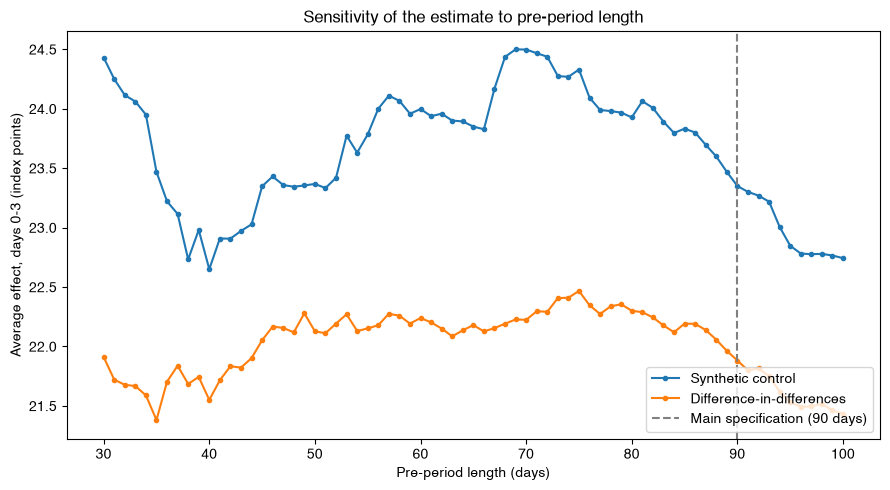

In [22]:
pre_lengths = range(30, 101)
sensitivity = pd.DataFrame({
    name: [fn(full_df.loc[event_date - pd.Timedelta(days=d):end_date], event_date)[1] for d in pre_lengths]
    for name, fn in {'Synthetic control': sc_effects, 'Difference-in-differences': did_effects}.items()
}, index=pd.Index(pre_lengths, name='pre-period length (days)'))
print(sensitivity.agg(['min', 'max']).round(1))
print(f"Spread (max - min): {(sensitivity.max() - sensitivity.min()).round(2).to_dict()}")
print(f"Synthetic control with a 60-day pre-period (as in the placebo backtest): {sensitivity.loc[placebo_pre, 'Synthetic control']:.1f}")

fig, ax = plt.subplots(figsize=(9, 5))
sensitivity.plot(ax=ax, marker='o', markersize=3)
ax.axvline(preperiod_length, color='gray', linestyle='--', label='Main specification (90 days)')
ax.set(xlabel='Pre-period length (days)', ylabel='Average effect, days 0-3 (index points)',
       title='Sensitivity of the estimate to pre-period length')
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig(FIG_DIR / 'sensitivity.png', dpi=150)

**Result.** The synthetic control estimate stays between 22.7 and 24.5 points across all 71 pre-period lengths, and DiD between 21.4 and 22.5. Neither depends materially on the pre-period choice. DiD varies slightly less (a spread of 1.1 against 1.8 points), because its weights are fixed rather than estimated.

**Post-period length and duration.** The headline averages over days 0–3. Extending the synthetic control counterfactual through the end of the data shows how long the lift lasts and how the average depends on the window chosen.

In [23]:
extended = full_df.loc[start_date:]
counterfactual = extended[controls] @ sc_weights + sc_level
daily_lift = extended[treated] - counterfactual
post_lift = daily_lift.loc[event_date:]

window_avg = pd.Series({k: post_lift.iloc[:k + 1].mean() for k in [0, 1, 3, 7, 10, len(post_lift) - 1]},
                       name='average lift, days 0-k')
print(f'Cumulative lift, days 0-3: {post_lift.iloc[:4].sum():.0f} index-days, of which day 0: {post_lift.iloc[0] / post_lift.iloc[:4].sum():.0%}')
print(f'Day 0: actual {extended.loc[event_date, treated]:.0f} vs. counterfactual {counterfactual.loc[event_date]:.1f} '
      f'({extended.loc[event_date, treated] / counterfactual.loc[event_date]:.1f}x)')
print(f'Average daily lift, days 4-{len(post_lift) - 1}: {post_lift.iloc[4:].mean():.1f}')
own_baseline = full_df.loc[event_date - pd.Timedelta(days=30):event_date - pd.Timedelta(days=1), treated].mean()
print(f"Day-0 lift against NerdWallet's own 30-day average ({own_baseline:.1f}): {extended.loc[event_date, treated] - own_baseline:.1f}")
display(post_lift.iloc[:4].round(1).rename('daily lift, days 0-3').to_frame().T)
window_avg.round(1).to_frame().T

Cumulative lift, days 0-3: 93 index-days, of which day 0: 67%
Day 0: actual 100 vs. counterfactual 37.3 (2.7x)
Average daily lift, days 4-18: 1.3
Day-0 lift against NerdWallet's own 30-day average (51.5): 48.5


date,2025-02-10,2025-02-11,2025-02-12,2025-02-13
"daily lift, days 0-3",62.7,12.3,9.0,9.4


,0,1,3,7,10,18
"average lift, days 0-k",62.7,37.5,23.3,10.3,8.2,5.9


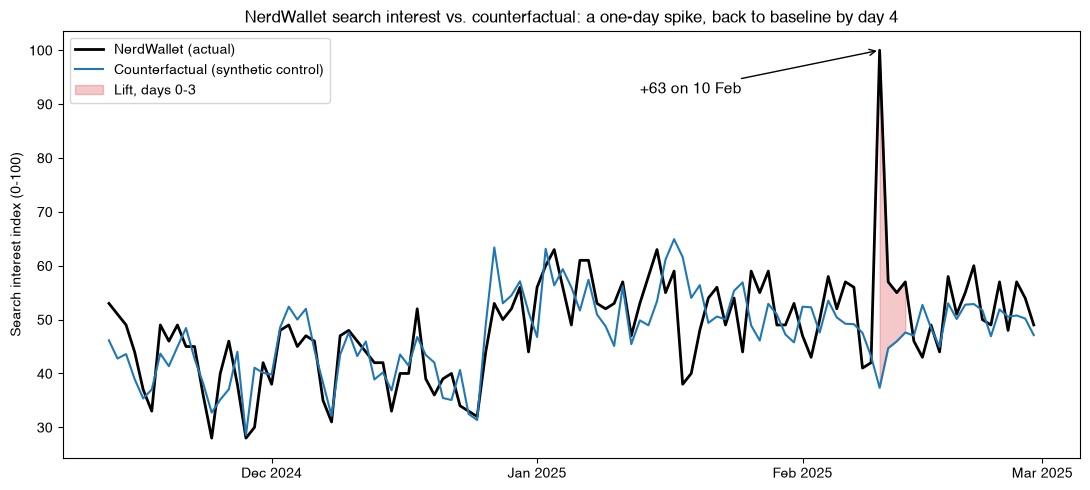

In [24]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(extended.index, extended[treated], color='black', linewidth=2, label='NerdWallet (actual)')
ax.plot(extended.index, counterfactual, color='tab:blue', linewidth=1.5, label='Counterfactual (synthetic control)')
post_window = extended.index[(extended.index >= event_date) & (extended.index <= end_date)]
ax.fill_between(post_window, counterfactual.loc[post_window], extended.loc[post_window, treated],
                color='tab:red', alpha=0.25, label='Lift, days 0-3')
ax.annotate(f'+{post_lift.iloc[0]:.0f} on 10 Feb', xy=(event_date, extended.loc[event_date, treated]),
            xytext=(event_date - pd.Timedelta(days=28), 92), arrowprops={'arrowstyle': '->'}, fontsize=11)
ax.set(title='NerdWallet search interest vs. counterfactual: a one-day spike, back to baseline by day 4',
       ylabel='Search interest index (0-100)')
format_date_axis(ax)
ax.legend(loc='upper left')
fig.tight_layout()
fig.savefig(FIG_DIR / 'lift_vs_counterfactual.png', dpi=150)

**Result.** The daily lift is 62.7 points on day 0, then 12.3, 9.0 and 9.4 on days 1–3, and averages 1.3 points over the remaining 15 days of February, indistinguishable from noise. Day 0 accounts for about two-thirds (67%) of the cumulative 4-day lift of 93 index-days. Because the effect is front-loaded, the average depends heavily on the window: 37.5 points over days 0–1, 23.3 over days 0–3 and 10.3 over days 0–7. That is why the day-0 effect is reported next to the 4-day average.

**Other specification choices**

| Variation | Average effect, days 0–3 |
|---|---|
| Synthetic control: weights fitted on demeaned data | 22.6 |
| Synthetic control: no level shift | 20.8 |
| Synthetic control: unconstrained Lasso weights, `alpha = 0.1` vs. cross-validated | 21.5 vs. 21.3 |
| Difference-in-differences instead of the synthetic control | 21.9 |
| Event study: single post indicator vs. daily indicators | 20.6 vs. 21.6 |
| Placebo backtest window (60-day pre-period) at the real event: synthetic control | 24.0 |

**What these checks do not test.** DiD, the event study and the synthetic control all rely on the same three control queries. Their agreement shows the result does not depend on *how* the controls are combined. It cannot show that the controls themselves were unaffected by the ad. ITS, which leans most on NerdWallet's own history, gives a lower but still large 13–17 points.

## 8. Conclusions

**Finding.** The Super Bowl ad produced a large, front-loaded lift in NerdWallet brand search. Search interest was about **63 index points above** the counterfactual on 10 February, roughly 2.7 times the expected level, and **23 points above it on average over days 0–3** (95% interval 17 to 36). About two-thirds of the 4-day lift came on day 0, and search interest was back near baseline from day 4.

**Why this is a credible causal estimate.** A randomized experiment was not possible, since the ad aired nationally. The estimate instead compares NerdWallet with a weighted average of three personal-finance searches that follow the same seasonal pattern but had no reason to respond to a NerdWallet ad. Before the ad, this synthetic NerdWallet tracked the real one, including through the turn-of-year rise, and there was no unusual movement in the week before the broadcast. To test the method itself, I re-ran it on 38 dates when no ad aired. None of those runs produced an effect close to the one measured, which also gives an empirical confidence interval that does not rely on textbook regression assumptions.

The result does not depend on the modelling choices. Four methods that build the counterfactual differently give 13–23 points for the 4-day average, and DiD, the daily event study and the synthetic control, which build the counterfactual directly from the control searches, give 21.6–23.3. Five ways of fitting the synthetic control give 20.8–23.3, and the preferred estimate stays between 22.7 and 24.5 across pre-periods from 30 to 100 days. The main assumption that cannot be tested is that the ad did not change searches for the control terms. If it raised them, the lift is understated; if it lowered them, for example because viewers searched NerdWallet instead, the lift is overstated. The controls dip slightly on day 0, so the day-0 estimate may be on the high side: against NerdWallet's own 30-day average it is 48.5 points rather than 62.7.

**Limitations**
- Google Trends reports a relative index, not search volume. Values are sampled and rescaled for every query (NerdWallet's day 0 is the 100 anchor here), so the index-point estimates apply to this export only, and repeated pulls would quantify the sampling noise.
- NerdWallet is measured as a Trends *topic*, while the controls are literal search terms.
- The control average dips on day 0, mainly because credit card points falls. Measured against NerdWallet's own 30-day average instead, the day-0 lift is 48.5 points rather than 62.7 (Section 7).
- The synthetic control and DiD both rely on only three control queries, and the preferred specification was chosen from several candidates on the same placebo dates.
- Other Super Bowl-day events could have moved finance searches, though none plausibly explains a NerdWallet-specific single-day spike.

**Implications**
- About two-thirds of the measurable lift arrives within roughly 24 hours of the broadcast. Paid-search budgets and caps, landing pages and site capacity should be sized for day 0 rather than spread over the following week.
- The lift is back near baseline by day 4. Any retargeting or follow-up campaign has a window of a few days, not weeks.

**Next steps**
- Translate the index lift into business value by mapping it to absolute search volume, site sessions and sign-ups for the same days.
- Measure future tentpole campaigns with a geo-holdout design, which estimates the lift experimentally. A larger pool of control queries would also make the synthetic control less dependent on any single donor.